# Análisis Diagnóstico de Filtros Adaptativos sobre el Conjunto de Prueba

Este notebook complementario carga únicamente `optimized_models_config.json` y el conjunto de prueba no visto (`IEEEPPG_TEST.ts`, $1328$ ventanas) —sin reejecutar optimización ni usar ventanas de entrenamiento— para generar los diagnósticos del comportamiento adaptativo y las pruebas de ablación y sensibilidad sobre **Test**:

1. **Puntos de operación y pasos efectivos ($\mu_{\text{ef}}$):** comparación de estabilidad teórica ($2/L$), paso efectivo LMS vs. NLMS/VS-LMS y desajuste teórico de RLS.
2. **Modos propios de $\hat{\mathbf{R}}$, curvas de aprendizaje en frío ($\text{WS}=0$) y estabilidad de $\|\mathbf{w}[n]\|_2$:** generación de `09_modos_y_aprendizaje_test.png`.
3. **Ablación de componentes, compromiso de dilatación ($D\in\{1,2,3,4\}$) y sensibilidad de RLS en $200$ ventanas estratificadas de prueba ($20$ por sujeto):** generación de `08_sensibilidad_RLS_test.png`.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

cwd = os.path.abspath(os.getcwd())
if os.path.basename(cwd) in ("implementation", "restructured_implementation"):
    IMPL_DIR, PROJECT_ROOT = cwd, os.path.abspath(os.path.join(cwd, ".."))
elif os.path.isdir(os.path.join(cwd, "implementation")):
    IMPL_DIR, PROJECT_ROOT = os.path.join(cwd, "implementation"), cwd
else:
    IMPL_DIR, PROJECT_ROOT = cwd, cwd

for p in (IMPL_DIR, PROJECT_ROOT):
    if p not in sys.path:
        sys.path.insert(0, p)

from dataset_preparation import FS, WIN, load_ts, get_participant_groups
from preprocessing import preprocess_signal
from reference_construction import build_U
from fusion import snr_weighted_late_fusion
from bpm_detection import zero_padded_periodogram_bpm
from optimization import MAX_M, load_optimization_config, OPTIMAL_LMS_PARAMS
import LMS_algorithms as LMSA

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "axes.grid": True, "grid.alpha": 0.28,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
})

SEED = 0
PER_SUBJ = 20
N_CURVE = 150
OUTLIER_BPM = 10.0
FIG_DIR = os.path.join(IMPL_DIR, "figuras_diagnostico_test")
os.makedirs(FIG_DIR, exist_ok=True)


def find_file(filename):
    for d in [IMPL_DIR, PROJECT_ROOT, os.getcwd(),
              os.path.join(PROJECT_ROOT, "ITBA_PAdSA_Proyecto_2", "implementation"),
              "/content", "/content/drive/MyDrive"]:
        cand = os.path.join(d, filename)
        if os.path.isfile(cand):
            return cand
    raise FileNotFoundError(f"No se encontró '{filename}'")


cfg = load_optimization_config(find_file("optimized_models_config.json"))
algos = cfg["algorithms"]
RLS_M, RLS_PARAMS = int(algos["rls"]["M"]), dict(algos["rls"]["lms_params"])
NLMS_M, NLMS_PARAMS = int(algos["nlms"]["M"]), dict(algos["nlms"]["lms_params"])
VS_LMS_M, VS_LMS_PARAMS = int(algos["vs_lms"]["M"]), dict(algos["vs_lms"]["lms_params"])
LMS_M = int(OPTIMAL_LMS_PARAMS["M"])
LMS_PARAMS = dict(mu=float(OPTIMAL_LMS_PARAMS["mu"]),
                  delay_step=int(RLS_PARAMS["delay_step"]),
                  huber_c=float(RLS_PARAMS["huber_c"]),
                  warm_start_ratio=float(RLS_PARAMS["warm_start_ratio"]))

X_test, y_test = load_ts(find_file("IEEEPPG_TEST.ts"))
test_groups = get_participant_groups(X_test)
rng = np.random.default_rng(SEED)

# Subconjunto estratificado: 20 ventanas aleatorias por cada uno de los 10 sujetos de prueba (200 ventanas)
sub_idx = []
for g in np.unique(test_groups):
    g_idx = np.where(test_groups == g)[0]
    pick = rng.choice(g_idx, size=min(PER_SUBJ, len(g_idx)), replace=False)
    sub_idx.append(pick)
sub_idx = np.sort(np.concatenate(sub_idx))
curve_idx = np.sort(rng.choice(len(X_test), size=min(N_CURVE, len(X_test)), replace=False))

p1_sub, p2_sub, ac_sub = preprocess_signal(X_test[sub_idx])
d_f_sub = np.array([snr_weighted_late_fusion(p1_sub[i], p2_sub[i]) for i in range(len(sub_idx))])
base_sub = np.array([zero_padded_periodogram_bpm(s, nfft=8192, window_type="hann") for s in d_f_sub])
y_sub = y_test[sub_idx]

p1_cur, p2_cur, ac_cur = preprocess_signal(X_test[curve_idx])

COLORS = {"lms": "#9467bd", "nlms": "#1f77b4", "vs_lms": "#2ca02c", "rls": "#d62728", "naive": "#ff7f0e"}
print(f"Cargado IEEEPPG_TEST: {X_test.shape} | Subconjunto estratificado: {len(y_sub)} ({len(np.unique(test_groups))} sujetos x {PER_SUBJ}) | Modos/curvas: {len(curve_idx)}")


Matplotlib created a temporary config/cache directory at /tmp/matplotlib-ntvj8u5n because the default path (/home/thomas/.config/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


Cargado IEEEPPG_TEST: (1328, 5, 1000) | Subconjunto estratificado: 200 (10 sujetos x 20) | Modos/curvas: 150


## 1. Puntos de operación teóricos, espectro de $\hat{\mathbf{R}}$, curvas de aprendizaje ($\text{WS}=0$) y estabilidad de pesos en Test

In [2]:
# --- 1A. Pasos efectivos, cotas de estabilidad y desajuste teórico ---
L_lms, L_nlms, L_vs, L_rls = 3 * LMS_M, 3 * NLMS_M, 3 * VS_LMS_M, 3 * RLS_M
mu_ef_nlms_samples = []
mu_ef_vs_min, mu_ef_vs_max = [], []
for a in ac_cur:
    U_nl = build_U(a, M=NLMS_M, delay_step=int(NLMS_PARAMS["delay_step"]))
    nrm_nl = np.einsum("ij,ij->i", U_nl, U_nl)
    mu_ef_nlms_samples.append(NLMS_PARAMS["mu"] / (NLMS_PARAMS["delta"] + nrm_nl))

    U_vs = build_U(a, M=VS_LMS_M, delay_step=int(VS_LMS_PARAMS["delay_step"]))
    nrm_vs = np.einsum("ij,ij->i", U_vs, U_vs)
    mu_ef_vs_min.append(VS_LMS_PARAMS["mu_min"] / (VS_LMS_PARAMS["delta"] + nrm_vs))
    mu_ef_vs_max.append(VS_LMS_PARAMS["mu_max"] / (VS_LMS_PARAMS["delta"] + nrm_vs))

mu_ef_nlms_all = np.concatenate(mu_ef_nlms_samples)
mu_ef_lms = LMS_PARAMS["mu"]
mu_ef_nlms_theo = NLMS_PARAMS["mu"] / (NLMS_PARAMS["delta"] + L_nlms)
lam_rls = float(RLS_PARAMS.get("lam", 1.0 - 1.0 / RLS_PARAMS["N_eff"]))
delta0_rls = float(RLS_PARAMS["delta"]) * L_rls
misadj_rls_pct = 100.0 * ((1.0 - lam_rls) / (1.0 + lam_rls)) * L_rls
misadj_lms_pct = 100.0 * 0.5 * mu_ef_lms * L_lms

print("=== PUNTOS DE OPERACIÓN TEÓRICOS Y EMPÍRICOS (TEST) ===")
print(f"LMS    : M={LMS_M} (L={L_lms}), D={LMS_PARAMS['delay_step']}, mu={mu_ef_lms:.5f}, 2/L={2.0/L_lms:.5f}, "
      f"mu_ef={mu_ef_lms:.2e}, M_LMS~0.5*mu*L={misadj_lms_pct:.2f}%")
print(f"NLMS   : M={NLMS_M} (L={L_nlms}), D={NLMS_PARAMS['delay_step']}, mu={NLMS_PARAMS['mu']:.5f}, "
      f"delta={NLMS_PARAMS['delta']:.4f}, 2/L={2.0/L_nlms:.5f}, "
      f"mu_ef(teor=L)={mu_ef_nlms_theo:.2e}, emp_mean={mu_ef_nlms_all.mean():.2e}, "
      f"emp_med={np.median(mu_ef_nlms_all):.2e}, ratio LMS/NLMS={mu_ef_lms/mu_ef_nlms_all.mean():.2f}x")
print(f"VS-LMS : M={VS_LMS_M} (L={L_vs}), D={VS_LMS_PARAMS['delay_step']}, mu_ef_theo=["
      f"{VS_LMS_PARAMS['mu_min']/(VS_LMS_PARAMS['delta']+L_vs):.2e}, "
      f"{VS_LMS_PARAMS['mu_max']/(VS_LMS_PARAMS['delta']+L_vs):.2e}], "
      f"emp_med_range=[{np.median(mu_ef_vs_min):.2e}, {np.median(mu_ef_vs_max):.2e}]")
print(f"RLS    : M={RLS_M} (L={L_rls}), D={RLS_PARAMS['delay_step']}, N_eff={RLS_PARAMS['N_eff']:.2f} "
      f"(lam={lam_rls:.6f}), delta={RLS_PARAMS['delta']:.4f} (delta0={delta0_rls:.2f}), "
      f"conv_2L={2*L_rls} muestras ({2*L_rls/FS:.3f} s), M_RLS={misadj_rls_pct:.2f}%")

# --- 1B. Espectros de autovalores de R_hat = U^T U en 150 ventanas de Test ---
evals_d1_m15, evals_d3_m8, tr_d3, lmax_d3, cond_d1, cond_d3, cond_reg = [], [], [], [], [], [], []
evals_lms_norm = []
for a in ac_cur:
    U1 = build_U(a, M=15, delay_step=1)
    e1 = np.sort(np.linalg.eigvalsh(U1.T @ U1))[::-1]
    Uo = build_U(a, M=RLS_M, delay_step=int(RLS_PARAMS["delay_step"]))
    eo = np.sort(np.linalg.eigvalsh(Uo.T @ Uo))[::-1]
    Ul = build_U(a, M=LMS_M, delay_step=1)
    el = np.sort(np.linalg.eigvalsh(Ul.T @ Ul))[::-1] / a.shape[1]
    evals_d1_m15.append(e1)
    evals_d3_m8.append(eo)
    evals_lms_norm.append(el)
    tr_d3.append(eo.sum())
    lmax_d3.append(eo[0])
    cond_d1.append(e1[0] / max(e1[-1], 1e-12))
    cond_d3.append(eo[0] / max(eo[-1], 1e-12))
    cond_reg.append((eo[0] + delta0_rls) / (max(eo[-1], 0.0) + delta0_rls))

med_spec_d1 = np.median(evals_d1_m15, axis=0)
med_spec_d3 = np.median(evals_d3_m8, axis=0)
med_spec_d3_reg = med_spec_d3 + delta0_rls
med_lms_eig = np.median(evals_lms_norm, axis=0)

tau_fast_s = (1.0 / (2.0 * mu_ef_lms * med_lms_eig[0])) / FS
tau_p5_s = (1.0 / (2.0 * mu_ef_lms * max(med_lms_eig[4], 1e-12))) / FS
tau_p10_s = (1.0 / (2.0 * mu_ef_lms * max(med_lms_eig[9], 1e-12))) / FS
tau_med_s = (1.0 / (2.0 * mu_ef_lms * max(np.median(med_lms_eig), 1e-12))) / FS

print("\n=== ESPECTRO DE AUTOVALORES EN TEST (150 ventanas) ===")
print(f"D=1, M=15 (L=45): lmax_med={med_spec_d1[0]:.1f}, lmin_med={med_spec_d1[-1]:.3e}, cond_med={np.median(cond_d1):.2e}")
print(f"D=3, M=8  (L=24): tr_med={np.median(tr_d3):.0f}, lmax_med={np.median(lmax_d3):.1f}, "
      f"lmin_med={med_spec_d3[-1]:.3e}, cond_med={np.median(cond_d3):.2e}")
print(f"Con reg delta0={delta0_rls:.1f}: delta0/lmax={100*delta0_rls/np.median(lmax_d3):.2f}%, "
      f"cond_efectivo_med={np.median(cond_reg):.1f} ({(np.median(lmax_d3)+delta0_rls)/delta0_rls:.1f})")
print(f"LMS (D=1, M=11) tiempo de modo tau_i = 1/(2*mu*lam_i*fs): modo 1={tau_fast_s:.2f} s, modo 5={tau_p5_s:.2f} s, "
      f"modo 10={tau_p10_s:.1f} s, modo mediano={tau_med_s:.1f} s")


=== PUNTOS DE OPERACIÓN TEÓRICOS Y EMPÍRICOS (TEST) ===
LMS    : M=11 (L=33), D=3, mu=0.00070, 2/L=0.06061, mu_ef=7.00e-04, M_LMS~0.5*mu*L=1.15%
NLMS   : M=34 (L=102), D=2, mu=0.01459, delta=2.6353, 2/L=0.01961, mu_ef(teor=L)=1.39e-04, emp_mean=4.16e-04, emp_med=1.61e-04, ratio LMS/NLMS=1.68x
VS-LMS : M=25 (L=75), D=2, mu_ef_theo=[1.74e-04, 2.02e-03], emp_med_range=[2.05e-04, 2.38e-03]
RLS    : M=8 (L=24), D=3, N_eff=1881.38 (lam=0.999468), delta=9.9724 (delta0=239.34), conv_2L=48 muestras (0.384 s), M_RLS=0.64%



=== ESPECTRO DE AUTOVALORES EN TEST (150 ventanas) ===
D=1, M=15 (L=45): lmax_med=22022.3, lmin_med=-2.458e-12, cond_med=2.20e+16
D=3, M=8  (L=24): tr_med=23930, lmax_med=9487.6, lmin_med=2.439e-07, cond_med=3.98e+10
Con reg delta0=239.3: delta0/lmax=2.52%, cond_efectivo_med=40.6 (40.6)
LMS (D=1, M=11) tiempo de modo tau_i = 1/(2*mu*lam_i*fs): modo 1=0.33 s, modo 5=10.01 s, modo 10=10001.8 s, modo mediano=112974.5 s


=== CURVAS DE APRENDIZAJE EN FRÍO (WS=0, dB) ===
LMS          | t=0.04s:  -4.26 dB | t=0.38s(2L):  -4.51 dB | t=1.0s:  -5.55 dB | t=4.0s:  -5.55 dB | t=7.8s:  -6.91 dB
NLMS         | t=0.04s:  -4.48 dB | t=0.38s(2L):  -3.17 dB | t=1.0s:  -4.88 dB | t=4.0s:  -5.52 dB | t=7.8s:  -6.39 dB
VS-LMS       | t=0.04s:  -8.61 dB | t=0.38s(2L):  -4.16 dB | t=1.0s:  -3.85 dB | t=4.0s:  -5.27 dB | t=7.8s:  -5.81 dB
RLS (final)  | t=0.04s:  -4.97 dB | t=0.38s(2L):  -5.68 dB | t=1.0s:  -5.79 dB | t=4.0s:  -5.17 dB | t=7.8s:  -6.07 dB
RLS ingenuo  | t=0.04s: -18.89 dB | t=0.38s(2L): -33.41 dB | t=1.0s: -15.15 dB | t=4.0s: -16.18 dB | t=7.8s: -17.28 dB

=== ESTABILIDAD DE LA NORMA DE PESOS ||w[n]||_2 (PPG1, mediana y P95 en n=999) ===
LMS          | med(||w[end]||)=  0.277 | P95(||w[end]||)=   0.388 | med(max_n ||w||)=  0.330 | finitos=150/150
NLMS         | med(||w[end]||)=  0.158 | P95(||w[end]||)=   0.218 | med(max_n ||w||)=  0.179 | finitos=150/150
RLS (final)  | med(||w[end]||)=  0.382 | P95(||w[e

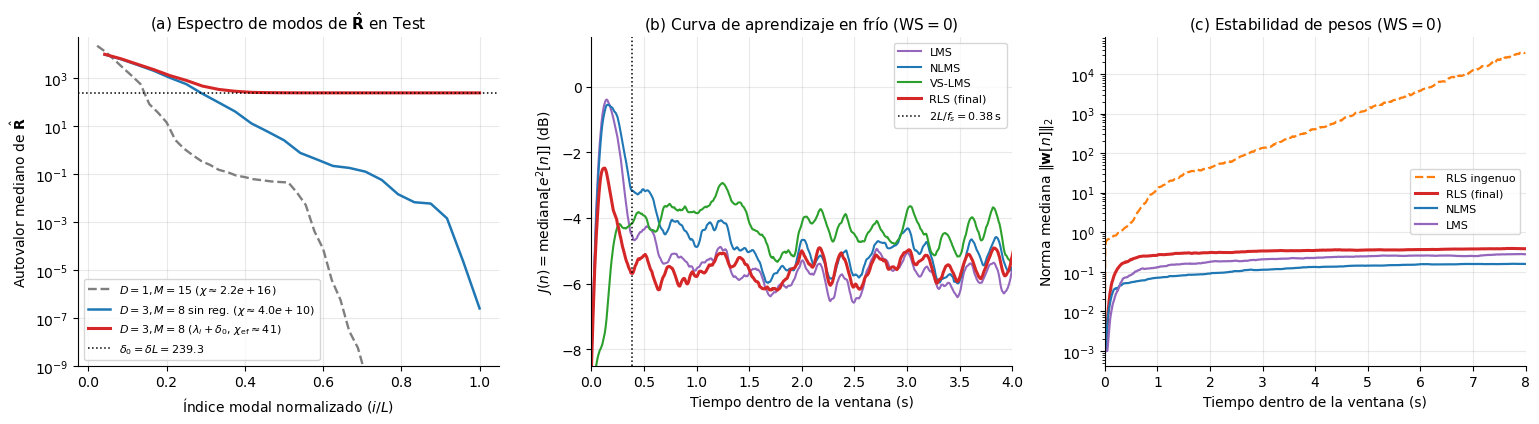

In [3]:
# --- 1C. Curvas de aprendizaje con arranque en frío (WS=0) y norma ||w[n]||_2 en Test ---
def trace_weight_norm_ppg1(d, acc, algo, M, params):
    N = len(d)
    D = int(params.get("delay_step", 1))
    U = build_U(acc, M=M, delay_step=D)
    L = U.shape[1]
    w = np.zeros(L, dtype=np.float64)
    wnorm = np.full(N, np.nan, dtype=np.float64)
    err = np.full(N, np.nan, dtype=np.float64)
    hc = params.get("huber_c", None)
    use_huber = hc is not None and float(hc) > 0.0
    hthr = float(hc) if use_huber else 0.0
    sigma_sq = 1.0

    if algo == "rls":
        lam = float(params["lam"]) if "lam" in params and params.get("N_eff") is None else 1.0 - 1.0 / float(params["N_eff"])
        inv_lam = 1.0 / lam
        p0 = 1.0 / (float(params["delta"]) * L)
        dl = float(params.get("diag_load", 0.0))
        tau_leak = float(np.clip((1.0 - lam) * dl, 0.0, 0.25))
        p_scale = inv_lam * (1.0 - tau_leak)
        diag_add = tau_leak * p0
        P = np.eye(L, dtype=np.float64) * p0
        idx = np.arange(L)
        for n in range(N):
            a_n = U[n]
            e_n = d[n] - float(np.dot(w, a_n))
            err[n] = e_n
            wnorm[n] = float(np.linalg.norm(w))
            if not np.isfinite(e_n) or abs(e_n) > 1e6:
                break
            e_upd, sigma_sq = LMSA._huber_clip(e_n, sigma_sq, hthr, use_huber)
            pi = P @ a_n
            denom = lam + float(np.dot(a_n, pi))
            if denom <= 1e-12:
                break
            inv_d = 1.0 / denom
            w += (e_upd * inv_d) * pi
            P -= inv_d * np.outer(pi, pi)
            P *= p_scale
            if tau_leak > 0.0:
                P[idx, idx] += diag_add
    elif algo == "nlms":
        mu = float(params["mu"]); delta = float(params["delta"])
        inv_den = mu / (delta + np.einsum("ij,ij->i", U, U))
        for n in range(N):
            a_n = U[n]
            e_n = d[n] - float(np.dot(w, a_n))
            err[n] = e_n
            wnorm[n] = float(np.linalg.norm(w))
            if not np.isfinite(e_n) or abs(e_n) > 1e6:
                break
            e_upd, sigma_sq = LMSA._huber_clip(e_n, sigma_sq, hthr, use_huber)
            w += (inv_den[n] * e_upd) * a_n
    elif algo == "lms":
        mu = float(params["mu"])
        for n in range(N):
            a_n = U[n]
            e_n = d[n] - float(np.dot(w, a_n))
            err[n] = e_n
            wnorm[n] = float(np.linalg.norm(w))
            if not np.isfinite(e_n) or abs(e_n) > 1e6:
                break
            e_upd, sigma_sq = LMSA._huber_clip(e_n, sigma_sq, hthr, use_huber)
            w += (mu * e_upd) * a_n
    return err, wnorm


cold_specs = {
    "lms": ("LMS", "lms", LMS_M, {**LMS_PARAMS, "warm_start_ratio": 0.0}),
    "nlms": ("NLMS", "nlms", NLMS_M, {**NLMS_PARAMS, "warm_start_ratio": 0.0}),
    "vs_lms": ("VS-LMS", "vs_lms", VS_LMS_M, {**VS_LMS_PARAMS, "warm_start_ratio": 0.0}),
    "rls": ("RLS (final)", "rls", RLS_M, {**RLS_PARAMS, "warm_start_ratio": 0.0}),
    "naive": ("RLS ingenuo", "rls", 15, dict(delay_step=1, N_eff=None, lam=0.98, delta=0.01/45.0, diag_load=0.0, huber_c=None, warm_start_ratio=0.0)),
}

J_curves = {}
for k, (_, algo, m_k, p_k) in cold_specs.items():
    P_arr = []
    for i in range(len(curve_idx)):
        _, det = LMSA.lms_bucket(p1_cur[i], p2_cur[i], ac_cur[i], algorithm=algo, M=m_k, return_details=True, **p_k)
        P_arr.append(0.5 * (det["e1"] ** 2 + det["e2"] ** 2))
    J_curves[k] = np.array(P_arr)

W_norms = {k: [] for k in ["lms", "nlms", "rls", "naive"]}
for i in range(len(curve_idx)):
    for k in ["lms", "nlms", "rls", "naive"]:
        _, algo, m_k, p_k = cold_specs[k]
        _, wn = trace_weight_norm_ppg1(p1_cur[i], ac_cur[i], algo, m_k, p_k)
        W_norms[k].append(wn)
for k in W_norms:
    W_norms[k] = np.array(W_norms[k])

t_axis = np.arange(WIN) / FS
print("=== CURVAS DE APRENDIZAJE EN FRÍO (WS=0, dB) ===")
for k, (lbl, _, _, _) in cold_specs.items():
    med = np.nanmedian(J_curves[k], axis=0)
    db = 10.0 * np.log10(uniform_filter1d(med, size=15, mode="nearest") + 1e-12)
    print(f"{lbl:<12} | t=0.04s: {db[5]:6.2f} dB | t=0.38s(2L): {db[48]:6.2f} dB | "
          f"t=1.0s: {db[125]:6.2f} dB | t=4.0s: {db[500]:6.2f} dB | t=7.8s: {db[975]:6.2f} dB")

print("\n=== ESTABILIDAD DE LA NORMA DE PESOS ||w[n]||_2 (PPG1, mediana y P95 en n=999) ===")
for k in ["lms", "nlms", "rls", "naive"]:
    w_fin = W_norms[k][:, -1]
    w_peak = np.nanmax(W_norms[k], axis=1)
    lbl = cold_specs[k][0]
    print(f"{lbl:<12} | med(||w[end]||)={np.nanmedian(w_fin):7.3f} | P95(||w[end]||)={np.nanpercentile(w_fin, 95):8.3f} "
          f"| med(max_n ||w||)={np.nanmedian(w_peak):7.3f} | finitos={np.sum(np.isfinite(w_fin))}/{len(w_fin)}")

# --- 1D. Figura 09_modos_y_aprendizaje_test.png ---
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.35))

ax = axes[0]
x_d1 = np.linspace(1.0 / 45.0, 1.0, 45)
x_d3 = np.linspace(1.0 / L_rls, 1.0, L_rls)
ax.semilogy(x_d1, med_spec_d1, "--", color="#7f7f7f", lw=1.7, label=rf"$D=1, M=15$ ($\chi\approx {np.median(cond_d1):.1e}$)")
ax.semilogy(x_d3, np.maximum(med_spec_d3, 1e-10), "-", color=COLORS["nlms"], lw=1.8, label=rf"$D=3, M=8$ sin reg. ($\chi\approx {np.median(cond_d3):.1e}$)")
ax.semilogy(x_d3, med_spec_d3_reg, "-", color=COLORS["rls"], lw=2.2, label=rf"$D=3, M=8$ ($\lambda_i+\delta_0$, $\chi_{{\mathrm{{ef}}}}\approx {np.median(cond_reg):.0f}$)")
ax.axhline(delta0_rls, color="k", ls=":", lw=1.1, label=rf"$\delta_0=\delta L={delta0_rls:.1f}$")
ax.set_ylim(1e-9, 5e4)
ax.set_xlabel(r"Índice modal normalizado ($i/L$)")
ax.set_ylabel(r"Autovalor mediano de $\hat{\mathbf{R}}$")
ax.set_title(r"(a) Espectro de modos de $\hat{\mathbf{R}}$ en Test")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
for k in ["lms", "nlms", "vs_lms", "rls"]:
    lbl = cold_specs[k][0]
    med = np.nanmedian(J_curves[k], axis=0)
    db = 10.0 * np.log10(uniform_filter1d(med, size=15, mode="nearest") + 1e-12)
    ax.plot(t_axis, db, color=COLORS[k], lw=2.2 if k == "rls" else 1.5, label=lbl)
ax.axvline(2 * L_rls / FS, color="k", ls=":", lw=1.1, label=rf"$2L/f_s = {2*L_rls/FS:.2f}\,\mathrm{{s}}$")
ax.set_xlim(0, 4.0)
ax.set_ylim(-8.5, 1.5)
ax.set_xlabel("Tiempo dentro de la ventana (s)")
ax.set_ylabel(r"$J(n) = \mathrm{mediana}[e^2[n]]$ (dB)")
ax.set_title(r"(b) Curva de aprendizaje en frío ($\mathrm{WS}=0$)")
ax.legend(fontsize=8, loc="upper right")

ax = axes[2]
for k in ["naive", "rls", "nlms", "lms"]:
    lbl = cold_specs[k][0]
    wmed = np.nanmedian(W_norms[k], axis=0)
    ax.semilogy(t_axis, np.maximum(wmed, 1e-3), color=COLORS[k], lw=2.2 if k == "rls" else 1.6,
                ls="--" if k == "naive" else "-", label=lbl)
ax.set_xlim(0, 8.0)
ax.set_xlabel("Tiempo dentro de la ventana (s)")
ax.set_ylabel(r"Norma mediana $\Vert\mathbf{w}[n]\Vert_2$")
ax.set_title(r"(c) Estabilidad de pesos ($\mathrm{WS}=0$)")
ax.legend(fontsize=8, loc="center right")

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "09_modos_y_aprendizaje_test.png"), dpi=220, bbox_inches="tight")
plt.show()


## 2. Ablación diagnóstica, compromiso de dilatación y sensibilidad de RLS sobre $200$ ventanas estratificadas de prueba

Subconjunto TEST estratificado (200 ventanas, Hann 8192): Base sin filtro AAE=19.72, MedAE=2.76, Out=40.0%


Evaluadas 32 configuraciones únicas en 415.9s.



=== ABLACIÓN EN 200 VENTANAS ESTRATIFICADAS DE PRUEBA ===
LMS Proy. 1 (D=1, M=11)                        | AAE=13.81 | MedAE=1.55 | Out=22.0% | NaN=0
LMS + estruc. RLS (D=3, M=11)                  | AAE=13.21 | MedAE=1.57 | Out=22.5% | NaN=0
NLMS Proy. 1 (D=1, M=22)                       | AAE=12.74 | MedAE=1.41 | Out=23.5% | NaN=0
NLMS + estruc. RLS (D=3, M=8)                  | AAE=12.44 | MedAE=1.55 | Out=23.5% | NaN=0
NLMS reoptimizado (D=2, M=34)                  | AAE=11.51 | MedAE=1.62 | Out=22.5% | NaN=0
VS-LMS Proy. 1 (D=1, M=18)                     | AAE=16.18 | MedAE=1.73 | Out=28.0% | NaN=0
VS-LMS + estruc. RLS (D=3, M=8)                | AAE=16.01 | MedAE=1.76 | Out=26.5% | NaN=0
VS-LMS reoptimizado (D=2, M=25)                | AAE=11.44 | MedAE=1.57 | Out=22.0% | NaN=0
RLS ingenuo (D=1, lam=0.98, delta=0.01)        | AAE=23.83 | MedAE=3.98 | Out=42.0% | NaN=0
RLS final (D=3, M=8)                           | AAE=10.96 | MedAE=1.49 | Out=22.0% | NaN=0
RLS final sin dilatac

{'D': 1, 'M': 22, 'L': 66, 'Apert_ms': 168.0, 'cond_med': 2.810614907500154e+16, 'AAE': 10.86, 'MedAE': 1.49, 'Out': 21.5, 'ms_win': 64.96}
{'D': 2, 'M': 11, 'L': 33, 'Apert_ms': 160.0, 'cond_med': 9998233751623358.0, 'AAE': 10.84, 'MedAE': 1.48, 'Out': 21.5, 'ms_win': 56.34}
{'D': 3, 'M': 8, 'L': 24, 'Apert_ms': 168.0, 'cond_med': 43379921703.877335, 'AAE': 10.96, 'MedAE': 1.49, 'Out': 22.0, 'ms_win': 67.55}
{'D': 4, 'M': 6, 'L': 18, 'Apert_ms': 160.0, 'cond_med': 15515904.053273859, 'AAE': 11.2, 'MedAE': 1.49, 'Out': 22.0, 'ms_win': 65.89}

Sensibilidad N_eff (TEST): [(150, 15.63, 1.71, 25.5), (300, 12.47, 1.7, 22.5), (600, 12.39, 1.52, 23.0), (1000, 11.67, 1.5, 22.5), (1881, 10.96, 1.49, 22.0), (2500, 11.19, 1.49, 22.5), (inf, 11.63, 1.5, 22.5)]
Sensibilidad delta (TEST): [(0.05, 20.42, 2.61, 35.5), (0.2, 15.45, 2.09, 27.0), (1.0, 13.15, 1.7, 23.5), (5.0, 11.85, 1.57, 23.0), (9.972, 10.96, 1.49, 22.0), (15.0, 11.33, 1.49, 21.5), (30.0, 10.87, 1.44, 21.0), (100.0, 11.21, 1.35, 21.0),

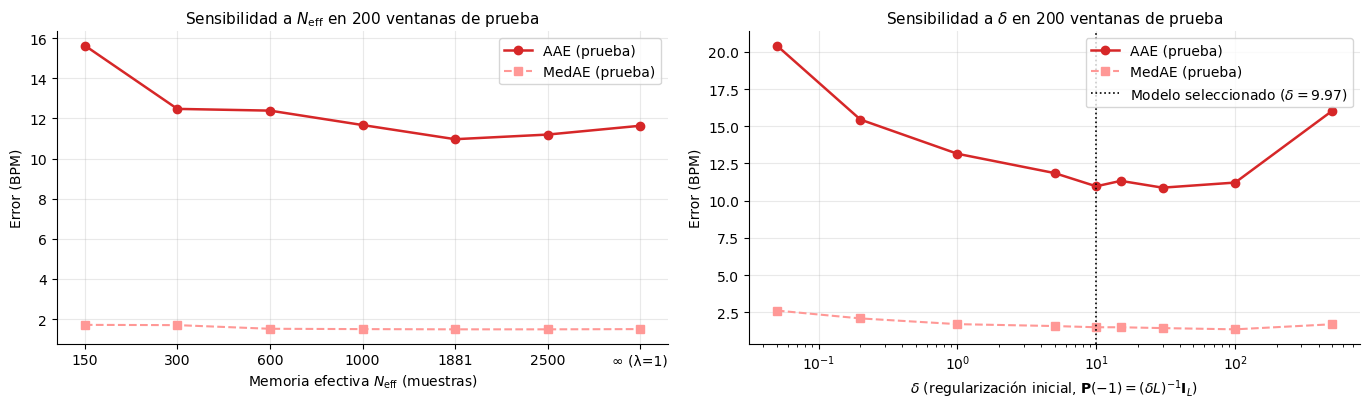

In [4]:
def fill_nan(p, fallback):
    p = np.asarray(p, dtype=float).copy()
    bad = ~np.isfinite(p)
    p[bad] = fallback[bad]
    return p, int(bad.sum())


def _canonical_key(algorithm, M, params):
    items = sorted((str(k), None if v is None else (round(float(v), 12) if isinstance(v, (int, float)) else str(v)))
                   for k, v in params.items())
    return (str(algorithm), int(M), tuple(items))


def eval_test_sub(algorithm, M, params):
    t0 = time.perf_counter()
    preds = np.empty(len(base_sub))
    for i in range(len(base_sub)):
        e = LMSA.lms_bucket(p1_sub[i], p2_sub[i], ac_sub[i], algorithm=algorithm, M=M, return_details=False, **params)
        preds[i] = zero_padded_periodogram_bpm(e, nfft=8192, window_type="hann")
    dt = time.perf_counter() - t0
    preds, n_bad = fill_nan(preds, base_sub)
    err = np.abs(preds - y_sub)
    return dict(aae=float(err.mean()), medae=float(np.median(err)),
                out=float(100.0 * np.mean(err > OUTLIER_BPM)), n_bad=n_bad, dt=float(dt))


def rls_with(**over):
    p = dict(RLS_PARAMS)
    for k, v in over.items():
        if v is None:
            p.pop(k, None)
        else:
            p[k] = v
    return p


RLS_D = int(RLS_PARAMS["delay_step"])
T_AP_SAMPLES = max(6, (RLS_M - 1) * RLS_D)
M_NODIL = max(6, min(MAX_M, T_AP_SAMPLES + 1))

base_err = np.abs(base_sub - y_sub)
print(f"Subconjunto TEST estratificado ({len(y_sub)} ventanas, Hann 8192): Base sin filtro "
      f"AAE={base_err.mean():.2f}, MedAE={np.median(base_err):.2f}, Out={100*np.mean(base_err > OUTLIER_BPM):.1f}%", flush=True)

SHARED = dict(delay_step=RLS_D, huber_c=RLS_PARAMS["huber_c"], warm_start_ratio=RLS_PARAMS["warm_start_ratio"])
variants = [
    ("LMS Proy. 1 (D=1, M=11)",                 "lms", "lms",    11, dict(mu=0.00070)),
    (f"LMS + estruc. RLS (D={RLS_D}, M=11)",    "lms", "lms",    11, dict(mu=0.00070, **SHARED)),
    ("NLMS Proy. 1 (D=1, M=22)",                "lms", "nlms",   22, dict(mu=0.01288, delta=0.5)),
    (f"NLMS + estruc. RLS (D={RLS_D}, M={RLS_M})", "lms", "nlms", RLS_M, dict(mu=0.01288, delta=0.5, **SHARED)),
    (f"NLMS reoptimizado (D={NLMS_PARAMS['delay_step']}, M={NLMS_M})", "lms", "nlms", NLMS_M, dict(NLMS_PARAMS)),
    ("VS-LMS Proy. 1 (D=1, M=18)",              "lms", "vs_lms", 18, dict(mu_max=0.06558, mu_min=0.00791, alpha=0.98503, gamma=0.00053, delta=1.0)),
    (f"VS-LMS + estruc. RLS (D={RLS_D}, M={RLS_M})", "lms", "vs_lms", RLS_M, dict(mu_max=0.06558, mu_min=0.00791, alpha=0.98503, gamma=0.00053, delta=1.0, **SHARED)),
    (f"VS-LMS reoptimizado (D={VS_LMS_PARAMS['delay_step']}, M={VS_LMS_M})", "lms", "vs_lms", VS_LMS_M, dict(VS_LMS_PARAMS)),
    ("RLS ingenuo (D=1, lam=0.98, delta=0.01)", "rls", "rls",    15, dict(delay_step=1, N_eff=None, lam=0.98, delta=0.01/45.0, diag_load=0.0, huber_c=None, warm_start_ratio=0.0)),
    (f"RLS final (D={RLS_D}, M={RLS_M})",      "rls", "rls",    RLS_M, dict(RLS_PARAMS)),
    (f"RLS final sin dilatación (D=1, M={M_NODIL})", "rls", "rls", M_NODIL, rls_with(delay_step=1)),
    ("RLS final sin Huber",                     "rls", "rls",    RLS_M, rls_with(huber_c=0.0)),
    ("RLS final sin carga diagonal",            "rls", "rls",    RLS_M, rls_with(diag_load=0.0)),
    ("RLS final sin olvido (lam=1)",            "rls", "rls",    RLS_M, rls_with(N_eff=None, lam=1.0)),
    ("RLS final + warm start (35%)",            "rls", "rls",    RLS_M, rls_with(warm_start_ratio=0.35)),
    ("RLS final con delta=0.05 (poca reg.)",    "rls", "rls",    RLS_M, rls_with(delta=0.05)),
]

# Deduplicar configuraciones compartidas entre ablación, dilatación a apertura fija y sensibilidad
jobs_map = {}
for _, _, algo, m_v, p_v in variants:
    k = _canonical_key(algo, m_v, p_v)
    jobs_map[k] = (algo, m_v, p_v)

dil_specs = []
for d_tr in (1, 2, 3, 4):
    m_tr = max(6, min(MAX_M, int(round(T_AP_SAMPLES / d_tr)) + 1))
    p_tr = rls_with(delay_step=d_tr)
    k = _canonical_key("rls", m_tr, p_tr)
    jobs_map[k] = ("rls", m_tr, p_tr)
    dil_specs.append((d_tr, m_tr, p_tr, k))

neff_opt = float(RLS_PARAMS["N_eff"])
neffs = sorted(set([150, 300, 600, 1000, int(round(neff_opt)), 2500])) + [np.inf]
delta_opt = float(RLS_PARAMS["delta"])
deltas = sorted(set([0.05, 0.2, 1.0, 5.0, round(delta_opt, 3), 15.0, 30.0, 100.0, 500.0]))

neff_keys = []
for n in neffs:
    p_n = rls_with(N_eff=None, lam=1.0) if np.isinf(n) else rls_with(N_eff=float(n))
    k = _canonical_key("rls", RLS_M, p_n)
    jobs_map[k] = ("rls", RLS_M, p_n)
    neff_keys.append(k)

delta_keys = []
for d in deltas:
    p_d = rls_with(delta=float(d))
    k = _canonical_key("rls", RLS_M, p_d)
    jobs_map[k] = ("rls", RLS_M, p_d)
    delta_keys.append(k)

t_all = time.perf_counter()
results_cache = {}
for idx_j, (k, (algo, m_v, p_v)) in enumerate(jobs_map.items(), 1):
    results_cache[k] = eval_test_sub(algo, m_v, p_v)
print(f"Evaluadas {len(jobs_map)} configuraciones únicas en {time.perf_counter() - t_all:.1f}s.", flush=True)

print("\n=== ABLACIÓN EN 200 VENTANAS ESTRATIFICADAS DE PRUEBA ===")
for name, fam, algo, m_v, p_v in variants:
    res = results_cache[_canonical_key(algo, m_v, p_v)]
    print(f"{name:<46} | AAE={res['aae']:5.2f} | MedAE={res['medae']:4.2f} | Out={res['out']:4.1f}% | NaN={res['n_bad']}")

print(f"\n=== COMPROMISO DE DILATACIÓN A APERTURA FIJA (~{T_AP_SAMPLES * 8.0:.0f} ms) EN TEST ===")
for d_tr, m_tr, p_tr, k in dil_specs:
    conds = []
    for a in ac_sub[:100]:
        Ut = build_U(a, M=m_tr, delay_step=d_tr)
        et = np.linalg.eigvalsh(Ut.T @ Ut)
        conds.append(et[-1] / max(et[0], 1e-12))
    r_tr = results_cache[k]
    ms_win = 1000.0 * r_tr["dt"] / len(y_sub)
    row = dict(D=d_tr, M=m_tr, L=3*m_tr, Apert_ms=round((m_tr-1)*d_tr*8.0, 1),
               cond_med=float(np.median(conds)), AAE=round(r_tr["aae"], 2),
               MedAE=round(r_tr["medae"], 2), Out=round(r_tr["out"], 1), ms_win=round(ms_win, 2))
    print(row)

r_neff = [results_cache[k] for k in neff_keys]
r_delta = [results_cache[k] for k in delta_keys]

print("\nSensibilidad N_eff (TEST):", [(n, round(r["aae"], 2), round(r["medae"], 2), round(r["out"], 1)) for n, r in zip(neffs, r_neff)])
print("Sensibilidad delta (TEST):", [(d, round(r["aae"], 2), round(r["medae"], 2), round(r["out"], 1)) for d, r in zip(deltas, r_delta)])

fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.2))
xs = np.arange(len(neffs))
axes[0].plot(xs, [r["aae"] for r in r_neff], "o-", color=COLORS["rls"], lw=1.8, label="AAE (prueba)")
axes[0].plot(xs, [r["medae"] for r in r_neff], "s--", color="#ff9896", lw=1.5, label="MedAE (prueba)")
axes[0].set_xticks(xs)
axes[0].set_xticklabels([("∞ (λ=1)" if np.isinf(n) else f"{n:g}") for n in neffs])
axes[0].set_xlabel(r"Memoria efectiva $N_{\mathrm{eff}}$ (muestras)")
axes[0].set_ylabel("Error (BPM)")
axes[0].set_title(r"Sensibilidad a $N_{\mathrm{eff}}$ en $200$ ventanas de prueba")
axes[0].legend()

axes[1].plot(deltas, [r["aae"] for r in r_delta], "o-", color=COLORS["rls"], lw=1.8, label="AAE (prueba)")
axes[1].plot(deltas, [r["medae"] for r in r_delta], "s--", color="#ff9896", lw=1.5, label="MedAE (prueba)")
axes[1].axvline(delta_opt, color="k", ls=":", lw=1.2, label=rf"Modelo seleccionado ($\delta={delta_opt:.2f}$)")
axes[1].set_xscale("log")
axes[1].set_xlabel(r"$\delta$ (regularización inicial, $\mathbf{P}(-1)=(\delta L)^{-1}\mathbf{I}_L$)")
axes[1].set_ylabel("Error (BPM)")
axes[1].set_title(r"Sensibilidad a $\delta$ en $200$ ventanas de prueba")
axes[1].legend()

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "08_sensibilidad_RLS_test.png"), dpi=220, bbox_inches="tight")
plt.show()
